# GloVe Implementation Using Mittens

**Objective:** Learn word embeddings using global word–context co-occurrence statistics.

Workflow:

1. Prepare the text corpus.
2. Tokenize the sentences.
3. Build the vocabulary.
4. Construct the co-occurrence matrix.
5. Train GloVe using `mittens`.
6. Evaluate embeddings using cosine similarity and nearest neighbors.

In [1]:
import re
import numpy as np
from collections import Counter
from mittens import GloVe

print("NumPy:", np.__version__)
print("GloVe library imported successfully!")

NumPy: 1.23.5
GloVe library imported successfully!


In [17]:
sentences = [
    # Royalty and relationships
    "king queen prince princess royal kingdom palace",
    "the king rules the kingdom from his royal palace",
    "the queen is the wife of the king",
    "the prince is the son of the king and queen",
    "the princess is the daughter of the king and queen",
    "the king and queen live in the palace",
    "the prince and princess belong to the royal family",

    # Gender and people
    "man woman boy girl person people",
    "the man is strong and the woman is strong",
    "the boy is young and the girl is young",
    "the man is the father of the boy",
    "the woman is the mother of the girl",
    "a boy grows into a man",
    "a girl grows into a woman",

    # Countries, cities and languages
    "paris is the capital of france",
    "berlin is the capital of germany",
    "rome is the capital of italy",
    "france paris french europe",
    "germany berlin german europe",
    "italy rome italian europe",
    "people in france speak french",
    "people in germany speak german",
    "people in italy speak italian",
    "paris berlin and rome are european cities",

    # Animals and pets
    "cat dog animal pet puppy kitten",
    "a cat is a small domestic animal",
    "a kitten is a young cat",
    "a puppy is a young dog",
    "dogs and cats are popular pets",
    "a dog is a loyal animal",
    "a cat can be a friendly pet",
    "puppies and kittens are young animals",

    # Machine learning and artificial intelligence
    "machine learning is a branch of artificial intelligence",
    "artificial intelligence allows machines to perform intelligent tasks",
    "deep learning is a branch of machine learning",
    "neural networks are used in deep learning",
    "a neural network contains interconnected neurons",
    "machine learning models learn patterns from data",
    "deep learning models learn complex patterns",
    "training data is used to train machine learning models",
    "artificial neural networks are inspired by the human brain",
    "data science uses statistics and machine learning",
    "a trained model makes predictions on new data",
    "natural language processing helps computers understand text",
    "computer vision helps machines understand images",
    "deep learning is used in computer vision and natural language processing",
] * 100

def tokenize(text):
    return re.findall(r"\b[a-z]+\b", text.lower())

tokenized_sentences = [tokenize(s) for s in sentences]

vocabulary = sorted(set(word for sent in tokenized_sentences for word in sent))
word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_idx.items()}

vocab_size = len(vocab)

print("Vocabulary size:", vocab_size)
print("Sample vocabulary:", vocab[:20])

Vocabulary size: 117
Sample vocabulary: ['a', 'allows', 'and', 'animal', 'animals', 'are', 'artificial', 'be', 'belong', 'berlin', 'boy', 'brain', 'branch', 'by', 'can', 'capital', 'cat', 'cats', 'cities', 'complex']


In [18]:
window_size = 2

cooccurrence = np.zeros(
    (vocab_size, vocab_size),
    dtype=np.float32
)

for sentence in tokenized_sentences:
    word_ids = [word_to_id[word] for word in sentence]

    for i, target_id in enumerate(word_ids):
        start = max(0, i - window_size)
        end = min(len(word_ids), i + window_size + 1)

        for j in range(start, end):
            if i == j:
                continue

            context_id = word_ids[j]
            distance = abs(i - j)

            cooccurrence[target_id, context_id] += 1.0 / distance

print("Co-occurrence matrix shape:", cooccurrence.shape)
print("Non-zero entries:", np.count_nonzero(cooccurrence))

Co-occurrence matrix shape: (117, 117)
Non-zero entries: 728


In [19]:
import pandas as pd

cooccurrence_df = pd.DataFrame(
    cooccurrence,
    index=vocabulary,
    columns=vocabulary
)

display(cooccurrence_df.round(2))

,a,allows,and,animal,animals,are,artificial,be,belong,berlin,...,train,trained,training,understand,used,uses,vision,wife,woman,young
a,0.0,0.0,0.0,50.0,0.0,0.0,0.0,100.0,0.0,0.0,...,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,200.0
allows,0.0,0.0,0.0,0.0,0.0,0.0,50.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
and,0.0,0.0,0.0,0.0,0.0,150.0,0.0,0.0,50.0,100.0,...,0.0,0.0,0.0,0.0,0.0,50.0,100.0,0.0,50.0,100.0
animal,50.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
animals,0.0,0.0,0.0,0.0,0.0,50.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
uses,0.0,0.0,50.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
vision,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
wife,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
woman,100.0,0.0,50.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [20]:
embedding_dim = 50

glove_model = GloVe(
    n=embedding_dim,
    max_iter=300,
    learning_rate=0.05
)

embeddings = glove_model.fit(cooccurrence)

print("Embedding matrix shape:", embeddings.shape)

Y:\Python\AI ML\Month 2\week 7-Deep Learning\.venv\lib\site-packages\tensorflow\python\client\session.py:1769: UserWarning: An interactive session is already active. This can cause out-of-memory errors in some cases. You must explicitly call `InteractiveSession.close()` to release resources held by the other session(s).
  warnings.warn('An interactive session is already active. This can '
Iteration 300: loss: 0.005294169299304485

Embedding matrix shape: (117, 50)


In [21]:
word_vectors = {
    word: embeddings[index]
    for word, index in word_to_id.items()
}

print("Vector for 'cats':")
print(word_vectors["cats"])

print("\nVector dimensions:", word_vectors["cats"].shape)

Vector for 'cats':
[ 0.5105979   0.804675    0.15285093 -0.04871735  0.6099364  -0.18527463
  0.38784558 -0.97220737  0.2617912   0.34039733  0.7292119   0.865085
 -0.62585676 -0.6774039   0.58312404  0.31104124  0.68183684 -0.24991854
 -0.36689496 -0.5172341   0.63275886  0.5360325  -0.5024787   0.4337961
  0.56398857 -0.6536099  -0.7049813  -0.01078019  0.6648817  -0.583784
 -0.31808573 -0.7304232  -0.7313228   0.0380124  -0.00182426 -0.62190604
 -0.7624074  -0.27296063  0.76744604 -0.16496633  0.02754067  0.5522462
 -0.80077004 -0.47402358 -0.3623875   0.34466106 -0.81827474 -0.22373241
 -0.6298686  -0.1663728 ]

Vector dimensions: (50,)


In [22]:
from sklearn.metrics.pairwise import cosine_similarity

def word_similarity(word1, word2):
    if word1 not in word_to_id or word2 not in word_to_id:
        raise ValueError("One or both words are not in the vocabulary.")

    vector1 = word_vectors[word1].reshape(1, -1)
    vector2 = word_vectors[word2].reshape(1, -1)

    return float(cosine_similarity(vector1, vector2)[0, 0])

In [23]:
pairs = [
    ("king", "queen"),
    ("king", "man"),
    ("paris", "france"),
    ("machine", "cat"),
]

for word1, word2 in pairs:
    print(
        f"{word1:10s} ↔ {word2:10s}: "
        f"{word_similarity(word1, word2):.4f}"
    )

king       ↔ queen     : 0.9204
king       ↔ man       : 0.6964
paris      ↔ france    : 0.8422
machine    ↔ cat       : 0.4663


In [24]:
def most_similar(word, top_k=5):
    if word not in word_to_id:
        raise ValueError(f"'{word}' is not in the vocabulary.")

    query_vector = word_vectors[word].reshape(1, -1)

    matrix = cosine_similarity(embeddings)
    similarities = matrix[word_to_id[word]].copy()

    # Exclude the query word itself
    similarities[word_to_id[word]] = -np.inf

    top_indices = np.argsort(similarities)[::-1][:top_k]

    return [
        (id_to_word[i], float(similarities[i]))
        for i in top_indices
    ]

In [25]:
for word in ["queen", "france", "machine", "german"]:
    print(f"\nNearest neighbors of '{word}':")

    for neighbor, score in most_similar(word, top_k=5):
        print(f"  {neighbor:12s} {score:.4f}")


Nearest neighbors of 'queen':
  king         0.9204
  and          0.8912
  live         0.8684
  prince       0.8378
  rules        0.8280

Nearest neighbors of 'france':
  french       0.8877
  paris        0.8422
  speak        0.8341
  germany      0.8225
  capital      0.7766

Nearest neighbors of 'machine':
  learning     0.9064
  deep         0.8862
  models       0.8382
  train        0.8339
  berlin       0.7333

Nearest neighbors of 'german':
  germany      0.8898
  europe       0.8321
  speak        0.8217
  berlin       0.8032
  french       0.7333


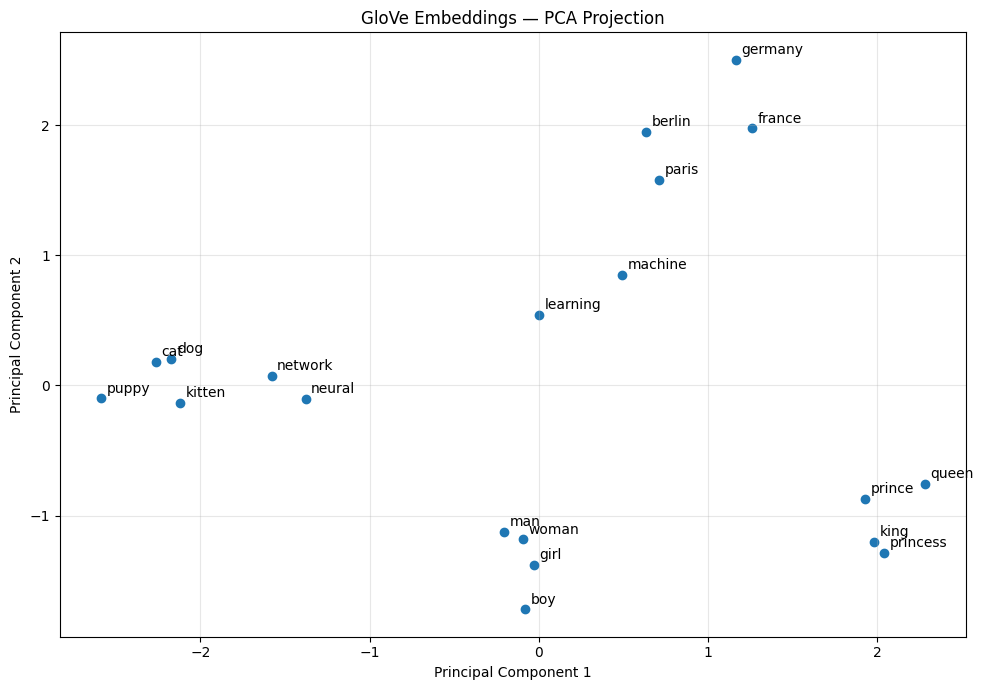

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Select words that exist in our GloVe vocabulary
words_to_plot = [
    "king", "queen", "prince", "princess",
    "man", "woman", "boy", "girl",
    "paris", "france", "berlin", "germany",
    "cat", "dog", "puppy", "kitten",
    "machine", "learning", "neural", "network"
]

# Check that all selected words exist
missing_words = [
    word for word in words_to_plot
    if word not in word_to_id
]

if missing_words:
    raise ValueError(f"Words missing from vocabulary: {missing_words}")

# Extract GloVe vectors (NumPy arrays; no torch.stack needed)
vectors = np.stack([
    embeddings[word_to_id[word]]
    for word in words_to_plot
])

# Reduce embedding dimensions to 2D
points_2d = PCA(n_components=2).fit_transform(vectors)

# Plot
plt.figure(figsize=(10, 7))
plt.scatter(points_2d[:, 0], points_2d[:, 1])

for i, word in enumerate(words_to_plot):
    plt.annotate(
        word,
        (points_2d[i, 0], points_2d[i, 1]),
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.title("GloVe Embeddings — PCA Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()